# Calibration 1: PD calibration for the logit and XGBoost models

**Goal:** make each model's PDs match the actual default rate, without changing how it ranks firms (AUC stays the same).

**Inputs:** the score files in `../Model_scores` (written by `04_train_logit.ipynb` and `train_xgb_imputed.ipynb`):
- train = 2007-2009, oot1 = 2010, oot2 = 2011. 2012 is not used: its 12-month default window runs past the end of the data, so every 2012 firm looks like a non-default.

**Years:** the final calibration is fitted on **all years (2007-2011)** for each model.

**Steps** (the same steps the harness uses, see `calibration.py` in the harness):
1. **Isotonic regression** maps the raw PD to the actual default rate, and never goes down as the raw PD goes up.
2. **Bayesian level adjustment** to the average default rate of the years used. With all years used for both steps, this is almost no change.
3. **Minimum PD of 0.05%** (Basel III final reforms floor for corporate exposures).
4. **Tie-break:** add 0.0001 x raw PD, so firms keep the model's order and AUC is exactly unchanged.

**Checks:** log loss (lower is better), AUC, mean PD vs actual default rate, overall, by period, and by decile.
**Extra check:** fit on 2007-2010 and test on 2011, a year the calibration has not seen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, log_loss
from scipy.stats import binom

SCORES_DIR = '../Model_scores'
PD_FLOOR, PD_CAP, TIE_BREAK = 0.0005, 0.9999, 1e-4
PERIOD = {'train': '2007-2009', 'oot1': '2010', 'oot2': '2011'}

MODELS = {
    'logit':   {s: f'scores_{s}_imputed_logit.csv' for s in PERIOD},
    'xgboost': {s: f'scores_{s}_imputed.csv' for s in PERIOD},
}

## Functions

In [2]:
def load(model):
    parts = []
    for split, file in MODELS[model].items():
        d = pd.read_csv(f'{SCORES_DIR}/{file}')[['y_true', 'y_pred']]
        d['period'] = PERIOD[split]
        parts.append(d)
    d = pd.concat(parts, ignore_index=True).dropna()
    d['y'] = d['y_true'].astype(int)
    d['raw'] = d['y_pred'].clip(PD_FLOOR, PD_CAP)     # raw model with the same 0.05% floor
    return d


def fit(raw, y):
    iso = IsotonicRegression(y_min=PD_FLOOR, y_max=PD_CAP, out_of_bounds='clip').fit(raw, y)
    return {'iso': iso, 'pi_s': iso.predict(raw).mean(), 'pi_t': y.mean()}


def apply(params, raw):
    p = params['iso'].predict(raw)                                    # 1. isotonic
    s, t = params['pi_s'], params['pi_t']
    p = t * (p - p * s) / (s - p * s + p * t - s * t)                 # 2. Bayesian level adjustment
    p = np.clip(p, PD_FLOOR, PD_CAP)                                  # 3. minimum PD 0.05%
    return p + TIE_BREAK * np.asarray(raw)                            # 4. tie-break (keeps AUC)


def scores(y, p):
    return {'firms': len(y), 'actual': y.mean(), 'mean_PD': np.mean(p),
            'log_loss': log_loss(y, p, labels=[0, 1]), 'AUC': roc_auc_score(y, p)}


def decile_table(y, raw, cal):
    t = pd.DataFrame({'y': y, 'raw': raw, 'cal': cal})
    t['decile'] = pd.qcut(t['raw'].rank(method='first'), 10, labels=False) + 1
    rows = []
    for dec, g in t.groupby('decile'):
        n, k, m = len(g), int(g.y.sum()), g.cal.mean()
        lo, hi = binom.ppf(0.025, n, m), binom.ppf(0.975, n, m)
        rows.append({'decile': dec, 'firms': n, 'actual': g.y.mean(), 'raw_PD': g.raw.mean(),
                     'calibrated_PD': m, 'defaults': k, 'expected': round(n * m),
                     'range_95': f'{lo:.0f}-{hi:.0f}', 'pass': lo <= k <= hi})
    return pd.DataFrame(rows).set_index('decile')

## Run for both models

In [3]:
results, deciles = {}, {}
for model in MODELS:
    d = load(model)

    # A. final calibration, fitted on all years
    params = fit(d['raw'], d['y'])
    d['cal'] = apply(params, d['raw'])
    deciles[model] = decile_table(d['y'], d['raw'], d['cal'])

    # B. check: fit on 2007-2010, test on 2011
    f, t = d[d.period != '2011'], d[d.period == '2011']
    t_cal = apply(fit(f['raw'], f['y']), t['raw'])

    results[model] = {'d': d, 't': t, 't_cal': t_cal}
    print(f'{model}: {len(d):,} firms, default rate {d.y.mean():.4%}, {len(params["iso"].X_thresholds_)} isotonic steps')

logit: 833,347 firms, default rate 1.4101%, 166 isotonic steps


xgboost: 833,348 firms, default rate 1.4101%, 218 isotonic steps


## A. All years (2007-2011): raw vs calibrated

In [4]:
rows = []
for model, r in results.items():
    d = r['d']
    for name, col in [('raw', 'raw'), ('calibrated', 'cal')]:
        rows.append({'model': model, 'version': name, **scores(d['y'], d[col])})
pd.DataFrame(rows).set_index(['model', 'version']).round(6)

firms    actual   mean_PD  log_loss       AUC
model   version                                                   
logit   raw         833347  0.014101  0.013909  0.067844  0.758082
        calibrated  833347  0.014101  0.014102  0.065838  0.758082
xgboost raw         833348  0.014101  0.013521  0.058016  0.857228
        calibrated  833348  0.014101  0.014104  0.057753  0.857228

## A. By period: mean PD vs actual, and log loss

In [5]:
rows = []
for model, r in results.items():
    for period, g in r['d'].groupby('period'):
        rows.append({'model': model, 'period': period, 'firms': len(g), 'actual': g.y.mean(),
                     'raw_PD': g.raw.mean(), 'cal_PD': g.cal.mean(),
                     'raw_log_loss': log_loss(g.y, g.raw, labels=[0, 1]),
                     'cal_log_loss': log_loss(g.y, g.cal, labels=[0, 1])})
pd.DataFrame(rows).set_index(['model', 'period']).round(6)

firms    actual    raw_PD    cal_PD  raw_log_loss  \
model   period                                                          
logit   2007-2009  475389  0.013989  0.013989  0.014138      0.066780   
        2010       174229  0.017029  0.013667  0.013894      0.080215   
        2011       183729  0.011615  0.013932  0.014208      0.058863   
xgboost 2007-2009  475389  0.013989  0.013952  0.014582      0.055036   
        2010       174229  0.017029  0.012817  0.013310      0.072418   
        2011       183730  0.011615  0.013074  0.013619      0.052068   

                   cal_log_loss  
model   period                   
logit   2007-2009      0.064779  
        2010           0.078181  
        2011           0.056874  
xgboost 2007-2009      0.054656  
        2010           0.072243  
        2011           0.052024

## A. By decile: logit

In [6]:
print(f"Deciles inside the 95% range: {int(deciles['logit']['pass'].sum())}/10")
deciles['logit'].round(4)

Deciles inside the 95% range: 8/10


,firms,actual,raw_PD,calibrated_PD,defaults,expected,range_95,pass
decile,,,,,,,,
1,83335,0.0044,0.0036,0.0038,365,313,278-348,False
2,83335,0.0032,0.0052,0.0038,270,314,280-349,False
3,83334,0.0045,0.0065,0.0044,373,369,332-407,True
4,83335,0.0053,0.0081,0.0053,441,444,403-485,True
5,83335,0.0072,0.0097,0.0072,599,599,552-648,True
6,83334,0.0086,0.0116,0.0085,714,711,660-764,True
7,83335,0.0116,0.0137,0.0116,969,968,908-1029,True
8,83334,0.0159,0.0166,0.0160,1326,1334,1264-1406,True
9,83335,0.0220,0.0208,0.0220,1837,1832,1750-1915,True


## A. By decile: XGBoost

In [7]:
print(f"Deciles inside the 95% range: {int(deciles['xgboost']['pass'].sum())}/10")
deciles['xgboost'].round(4)

Deciles inside the 95% range: 10/10


,firms,actual,raw_PD,calibrated_PD,defaults,expected,range_95,pass
decile,,,,,,,,
1,83335,0.0004,0.0009,0.0005,32,42,30-55,True
2,83335,0.0008,0.0016,0.0008,65,65,49-81,True
3,83335,0.0015,0.0024,0.0015,127,125,104-147,True
4,83334,0.0028,0.0035,0.0028,232,232,202-262,True
5,83335,0.0043,0.0049,0.0043,355,354,318-392,True
6,83335,0.0060,0.0067,0.0060,503,497,454-541,True
7,83334,0.0084,0.0091,0.0085,699,708,656-760,True
8,83335,0.0135,0.0128,0.0134,1122,1116,1051-1181,True
9,83335,0.0221,0.0203,0.0220,1838,1835,1753-1919,True


## A. Plot: predicted vs actual by decile

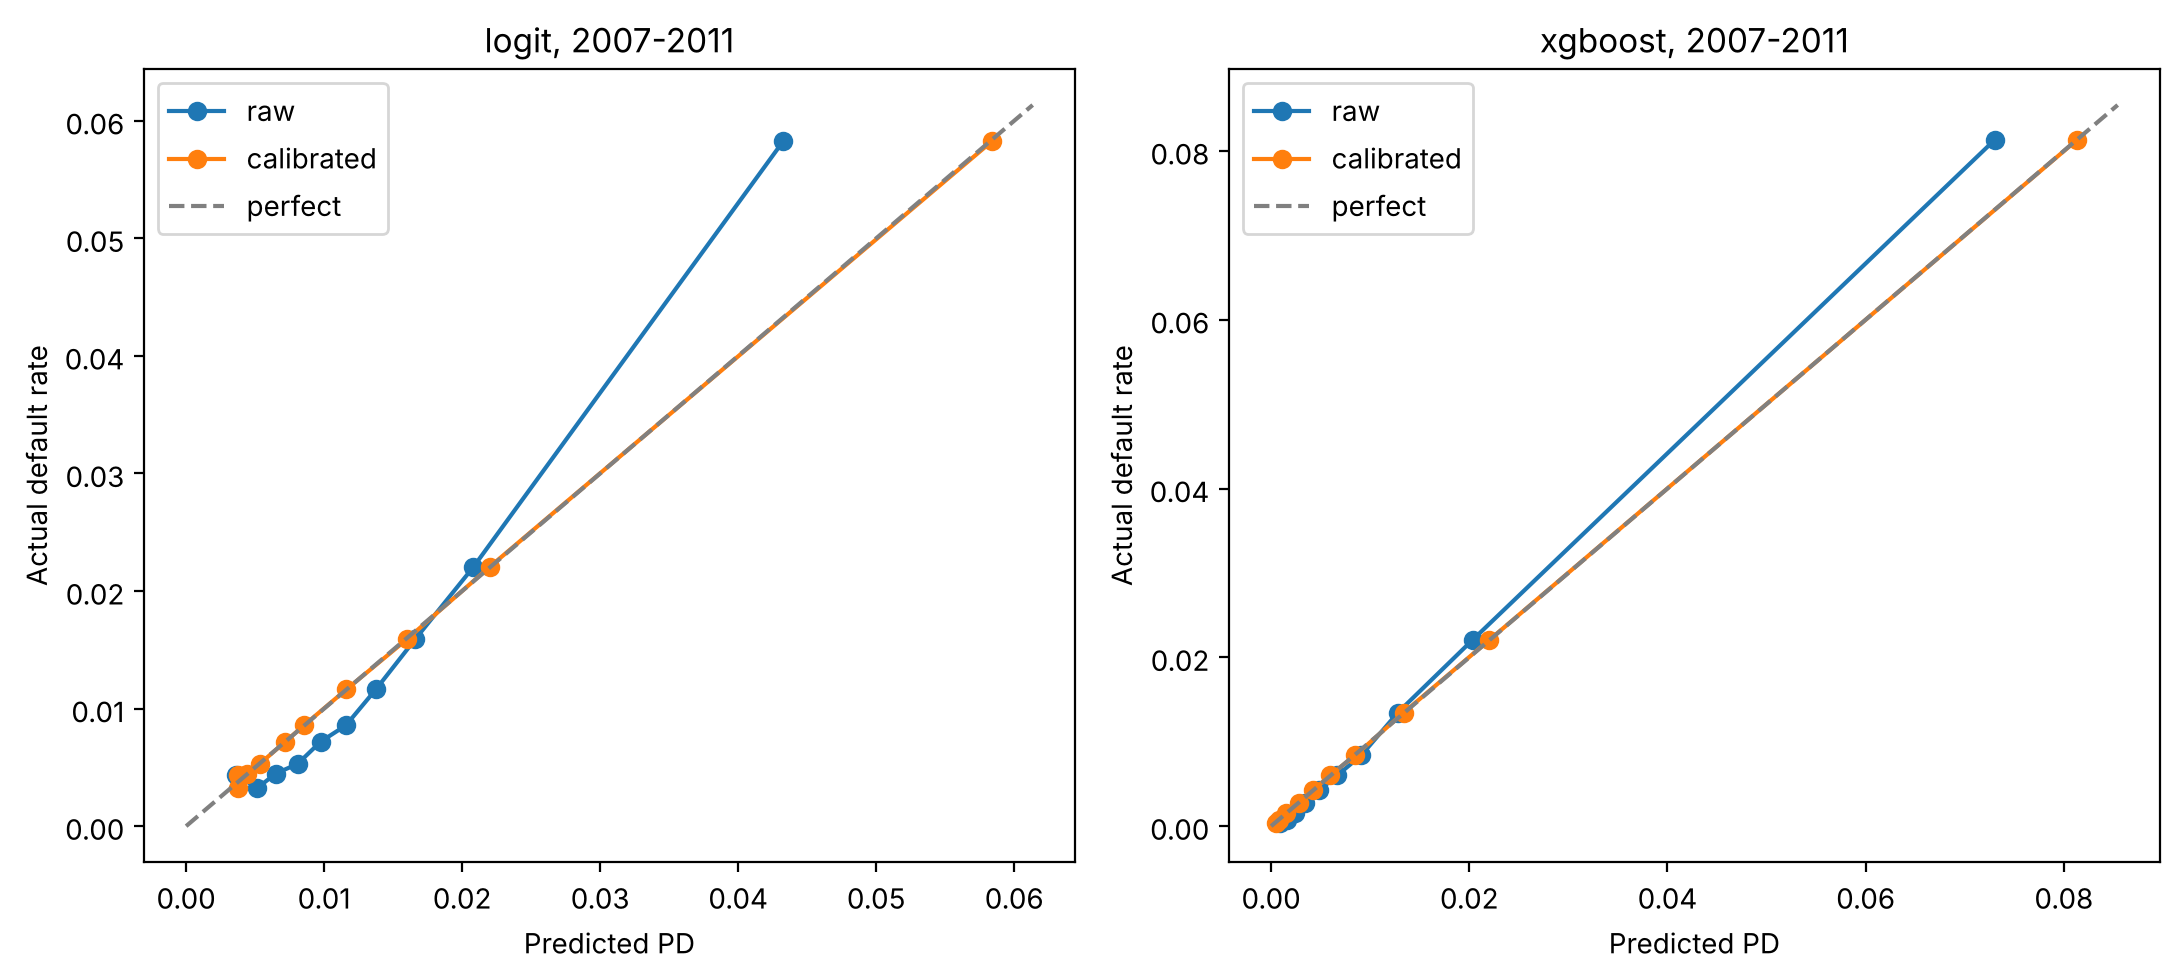

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, model in zip(axes, deciles):
    t = deciles[model]
    ax.plot(t.raw_PD, t.actual, 'o-', label='raw')
    ax.plot(t.calibrated_PD, t.actual, 'o-', label='calibrated')
    top = max(t[['raw_PD', 'calibrated_PD', 'actual']].max()) * 1.05
    ax.plot([0, top], [0, top], '--', color='grey', label='perfect')
    ax.set_title(f'{model}, 2007-2011'); ax.set_xlabel('Predicted PD'); ax.set_ylabel('Actual default rate')
    ax.legend()
plt.tight_layout(); plt.show()

## B. Check on a year the calibration has not seen (fit 2007-2010, test 2011)

In [9]:
rows = []
for model, r in results.items():
    rows.append({'model': model, 'version': 'raw', **scores(r['t']['y'], r['t']['raw'])})
    rows.append({'model': model, 'version': 'calibrated', **scores(r['t']['y'], r['t_cal'])})
pd.DataFrame(rows).set_index(['model', 'version']).round(6)

firms    actual   mean_PD  log_loss       AUC
model   version                                                   
logit   raw         183729  0.011615  0.013932  0.058863  0.764799
        calibrated  183729  0.011615  0.014963  0.057139  0.764799
xgboost raw         183730  0.011615  0.013074  0.052068  0.841070
        calibrated  183730  0.011615  0.014160  0.052387  0.841070

## Summary checks

In [10]:
rows = []
for model, r in results.items():
    d, t, tc = r['d'], r['t'], r['t_cal']
    rows.append({
        'model': model,
        'AUC unchanged': roc_auc_score(d.y, d.raw) == roc_auc_score(d.y, d.cal),
        'log loss lower (all years)': log_loss(d.y, d.cal) < log_loss(d.y, d.raw),
        'log loss lower (unseen 2011)': log_loss(t.y, tc) < log_loss(t.y, t.raw),
        'mean PD closer to actual': abs(d.cal.mean() - d.y.mean()) <= abs(d.raw.mean() - d.y.mean()),
        'no PD below 0.05%': d.cal.min() >= PD_FLOOR,
    })
pd.DataFrame(rows).set_index('model')

,AUC unchanged,log loss lower (all years),log loss lower (unseen 2011),mean PD closer to actual,no PD below 0.05%
model,,,,,
logit,True,True,True,True,True
xgboost,True,True,False,True,True


## AUC: original vs calibrated (12 decimals)
AUC only depends on the order of the PDs. Calibration keeps the order, so every row should say YES.

In [11]:
rows = []
for model, r in results.items():
    d = r['d']
    for period in ['2007-2009', '2010', '2011', 'All years']:
        g = d if period == 'All years' else d[d.period == period]
        a_raw, a_cal = roc_auc_score(g.y, g.raw), roc_auc_score(g.y, g.cal)
        rows.append({'model': model, 'period': period,
                     'AUC original': f'{a_raw:.12f}', 'AUC calibrated': f'{a_cal:.12f}',
                     'same?': 'YES' if a_raw == a_cal else 'NO'})
pd.DataFrame(rows).set_index(['model', 'period'])

AUC original  AUC calibrated same?
model   period                                         
logit   2007-2009  0.762709002799  0.762709002799   YES
        2010       0.744136450377  0.744136450377   YES
        2011       0.764798916959  0.764798916959   YES
        All years  0.758081887992  0.758081887992   YES
xgboost 2007-2009  0.878710309104  0.878710309104   YES
        2010       0.824471470394  0.824471470394   YES
        2011       0.841070238863  0.841070238863   YES
        All years  0.857227891029  0.857227891029   YES